# Reproducing *Opening the Black Box of Deep Neural Networks via Information*
**Paper:** Schwartz-Ziv & Tishby (2017), [arXiv:1703.00810](https://arxiv.org/abs/1703.00810) — ITCT mid-term project

**Contributors:** Apple Rose Buhisan Alce (Student ID D14949006) and Naveed Ullah (Student ID D14949002), Department of Computer Science and Information Engineering, National Taiwan University  
**Course:** Information Theory and Coding Techniques (CSIE7624), Fall 2026

This notebook re-implements the paper's experiments **from scratch in NumPy** (no deep-learning framework needed), reproduces its main figures, adds two controlled extra experiments, and ends with an **interactive information-plane explorer** (epoch slider) for all experiments.

| Paper figure / claim | Notebook section |
|---|---|
| Task: spherically-symmetric rule on 12 binary inputs, Eq. (10) | §1 |
| The network ensemble, trained in parallel | §2 |
| Mutual-information estimation by binning (30 bins) | §3 |
| SGD training with information-plane snapshots | §4 |
| Fig. 2 – layer snapshots in the information plane (epoch 0 / mid / end) | §5 |
| Fig. 4 – drift vs. diffusion phases (gradient mean vs. std, SNR) | §6 |
| Fig. 3 – information-plane trajectories for 5 % / 45 % / 85 % training data | §6 |
| Fig. 7 – converged layers vs. training-set size | §7 |
| Fig. 6 – layers vs. the Information-Bottleneck bound, β* from Eq. (12) | §8 |
| Fig. 5 – benefit of hidden layers (1…6 hidden layers) | §9 |
| Fig. 8 – a different (non-symmetric, committee-machine) rule | §10 |
| *Extra:* does compression survive a ReLU network? (with a peak-to-end table) | §11 |
| *Extra:* how sensitive is the compression result to the number of MI bins (10 / 30 / 100)? | §12 |
| **Interactive explorer:** epoch slider + play button for every experiment, exported as HTML | §13 |
| Automatic check of the paper's claims (i)–(iv) plus the two extras | §14 |
| Limitations and discussion | §15 |
| Export of all figures and of the explorer | §16 |

**Quick start.** *Runtime ▸ Run all.* A full run of the default preset takes roughly one hour on a free Colab CPU runtime (no GPU needed); every expensive result is cached (on Google Drive in Colab, see the config cell), so re-running the notebook afterwards takes about a minute. The interactive explorer is in §13.

**Design choices that make it fast.** All `n_nets` randomly initialised networks (the paper uses 50) are trained *simultaneously* as one batched tensor, each with its own initial weights, its own training sample and its own mini-batch order. Backprop is written by hand (tanh hidden layers, 2-neuron softmax output, cross-entropy, plain SGD).

**Presets.** Set in the config cell (or with the env-var `NB_PRESET`): `quick` (~5 min, smoke test), `standard` (~30 min), `long` (**default**: 20 nets × 10 000 epochs; all reported numbers), `paper` (50 networks × 10 000 epochs, a few hours).


In [1]:
import os, time, pickle, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib import colors
from scipy.special import eval_legendre, expit
try:
    from tqdm.auto import tqdm
except ImportError:                                   # tqdm is optional
    def tqdm(x, **kw): return x
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ======================= CONFIG =======================
PRESET = os.environ.get("NB_PRESET", "long")          # "quick" | "standard" | "long" | "paper"
PRESETS = {
    "quick":    dict(n_nets=5,  epochs=1500,  n_log=50, n_lin=25),
    "standard": dict(n_nets=20, epochs=5000,  n_log=70, n_lin=40),
    "long":     dict(n_nets=20, epochs=10000, n_log=80, n_lin=50),     # same as standard but trained to ~convergence
    "paper":    dict(n_nets=50, epochs=10000, n_log=90, n_lin=60),
}
CFG = PRESETS[PRESET]
N_NETS, EPOCHS = CFG["n_nets"], CFG["epochs"]

LR, BATCH, NBINS = 0.05, 1024, 30                     # SGD learning rate, mini-batch size, MI bins (paper: 30)
WIDTHS = [12, 10, 7, 5, 4, 3, 2]                      # main architecture (paper, Sec. 3.1)
TRAIN_FRACS = [0.03, 0.05, 0.10, 0.20, 0.30, 0.45, 0.60, 0.85]
SEED = 0
USE_CACHE, CACHE_DIR, FIG_DIR = True, "cache", "figures"
USE_DRIVE = True        # Colab only: keep cache and figures on Google Drive so a disconnect does not lose hours of training
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        import glob, shutil
        old_cache = CACHE_DIR                                   # reuse results of an earlier run in this runtime, if any
        CACHE_DIR, FIG_DIR = "/content/drive/MyDrive/itct_cache", "/content/drive/MyDrive/itct_figures"
        os.makedirs(CACHE_DIR, exist_ok=True)
        if os.path.isdir(old_cache) and not glob.glob(os.path.join(CACHE_DIR, "*.pkl")):
            for f in glob.glob(os.path.join(old_cache, "*.pkl")): shutil.copy(f, CACHE_DIR)
    except ImportError:
        pass                                                    # not running in Colab: keep the local folders
os.makedirs(CACHE_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
LAYER_COLORS = plt.cm.tab10(np.arange(10))

def cached(name, fn):
    """Run fn() once and pickle the result (keyed by preset) so long runs survive kernel restarts."""
    # the key contains the hyper-parameters, so changing LR/BATCH/... never silently reloads stale results
    tag = f"{PRESET}_lr{LR}_b{BATCH}_bins{NBINS}_w{'-'.join(map(str, WIDTHS))}"
    path = os.path.join(CACHE_DIR, f"{tag}_{name}.pkl")
    if USE_CACHE and os.path.exists(path):
        with open(path, "rb") as f: return pickle.load(f)
    out = fn()
    if USE_CACHE:
        with open(path, "wb") as f: pickle.dump(out, f)
    return out

def savefig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}_{PRESET}.png"), dpi=160, bbox_inches="tight")

print(f"preset = {PRESET}: {N_NETS} networks x {EPOCHS} epochs | lr={LR}, batch={BATCH}, bins={NBINS}")

Mounted at /content/drive
preset = long: 20 networks x 10000 epochs | lr=0.05, batch=1024, bins=30


## 1. The task: a spherically-symmetric rule on 12 binary inputs (paper §3.1)

* The 12 inputs are binary indicators of 12 uniformly spread points on a sphere — the **vertices of an icosahedron** — so there are $2^{12}=4096$ input patterns, all equally likely.
* For each pattern we compute a rotation-invariant function $f(x)$. The paper uses the **spherical-harmonics power spectrum** of the pattern (Kazhdan et al., 2003). By the addition theorem the energy in degree $\ell$ is
  $P_\ell(x)=\sum_{i,j} x_i x_j \,\tfrac{2\ell+1}{4\pi}\,P_\ell(\cos\theta_{ij})$ (Legendre polynomials), so we never need explicit harmonics. We take $f(x)=\sum_{\ell=1}^{6} w_\ell P_\ell(x)$ with random weights $w_\ell$.
* Label rule (Eq. 10): $p(y{=}1|x)=\psi(f(x)-\theta)$, $\psi(u)=1/(1+e^{-\gamma u})$, with $\theta$ chosen so $p(y{=}1)\approx 0.5$ and the gain $\gamma$ chosen so that $I(X;Y)\approx0.99$ bits.

patterns: (4096, 12) | P(y=1) = 0.497 | I(X;Y) = 0.990 bits | gain gamma = 85.3
distinct power-spectrum classes (paper: '64 orbits'): 64


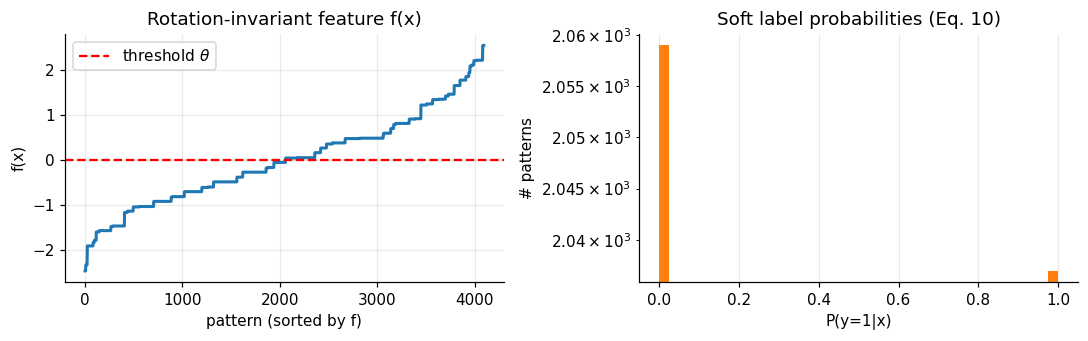

In [2]:
# ---------- information-theory helpers ----------
def H2(p):
    """Binary entropy in bits (vectorised)."""
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

def mutual_info_xy(py1):
    """I(X;Y) in bits for uniform P(x) and binary label with P(y=1|x)=py1[x]."""
    return float(H2(py1.mean()) - H2(py1).mean())

# ---------- the 12-point spherical task ----------
def icosahedron_vertices():
    phi = (1 + 5 ** 0.5) / 2
    v = []
    for s1 in (-1, 1):
        for s2 in (-1, 1):
            v += [(0, s1, s2 * phi), (s1, s2 * phi, 0), (s2 * phi, 0, s1)]
    v = np.array(v, float)
    return v / np.linalg.norm(v, axis=1, keepdims=True)

def all_patterns(n=12):
    idx = np.arange(2 ** n)[:, None]
    return ((idx >> np.arange(n - 1, -1, -1)) & 1).astype(np.float32)

def make_rule(seed=5, lmax=6, target_IXY=0.99):
    V = icosahedron_vertices(); X = all_patterns(12)
    cosm = np.clip(V @ V.T, -1, 1)
    G = np.stack([(2 * l + 1) / (4 * np.pi) * eval_legendre(l, cosm) for l in range(1, lmax + 1)])
    w = np.random.default_rng(seed).normal(size=lmax)
    raw = lambda Xp: np.einsum("ni,lij,nj->nl", Xp, G, Xp) @ w      # rotation-invariant power spectrum, mixed
    f0 = raw(X); mu, sd = f0.mean(), f0.std()
    f_of = lambda Xp: (raw(Xp) - mu) / sd
    f = f_of(X)
    # threshold theta: in the gap between two classes so that P(y=1) ~ 0.5
    vals, counts = np.unique(np.round(f, 8), return_counts=True)
    k = np.argmin(np.abs(np.cumsum(counts) / len(f) - 0.5))
    theta = 0.5 * (vals[k] + vals[k + 1])
    # gain gamma by bisection so that I(X;Y) = target
    lo, hi = 0.1, 1e4
    for _ in range(80):
        g = np.sqrt(lo * hi)
        lo, hi = (g, hi) if mutual_info_xy(expit(g * (f - theta))) < target_IXY else (lo, g)
    gamma = np.sqrt(lo * hi); py1 = expit(gamma * (f - theta))
    info = dict(gamma=gamma, theta=theta, f=f, f_of=f_of, n_classes=len(vals),
                p_y1=py1.mean(), IXY=mutual_info_xy(py1))
    return X, py1, info

X_ALL, PY1, RULE = make_rule()
print(f"patterns: {X_ALL.shape} | P(y=1) = {RULE['p_y1']:.3f} | I(X;Y) = {RULE['IXY']:.3f} bits | gain gamma = {RULE['gamma']:.1f}")
print(f"distinct power-spectrum classes (paper: '64 orbits'): {RULE['n_classes']}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(np.sort(RULE["f"]), lw=2); ax[0].axhline(RULE["theta"], color="r", ls="--", label=r"threshold $\theta$")
ax[0].set(xlabel="pattern (sorted by f)", ylabel="f(x)", title="Rotation-invariant feature f(x)"); ax[0].legend()
ax[1].hist(PY1, bins=40, color="C1"); ax[1].set_yscale("log")
ax[1].set(xlabel="P(y=1|x)", ylabel="# patterns", title="Soft label probabilities (Eq. 10)")
plt.tight_layout(); plt.show()

In [3]:
# ---- sanity check: is the rule really invariant under the icosahedral symmetry group? ----
V = icosahedron_vertices(); Gram = np.round(V @ V.T, 6)
perms = []
def _bt(assign):                       # all vertex permutations preserving the Gram matrix (= symmetry group)
    k = len(assign)
    if k == 12: perms.append(tuple(assign)); return
    for c in range(12):
        if c not in assign and all(abs(Gram[k, j] - Gram[c, assign[j]]) < 1e-5 for j in range(k)):
            _bt(assign + [c])
_bt([])
Xi = X_ALL.astype(int); pw = 1 << np.arange(11, -1, -1)
canon = Xi @ pw; max_dev = 0.0
for p in perms:
    Xp = np.zeros_like(Xi); Xp[:, list(p)] = Xi
    canon = np.minimum(canon, Xp @ pw)
    max_dev = max(max_dev, np.abs(RULE["f_of"](Xp.astype(np.float32)) - RULE["f"]).max())
print(f"symmetry group size: {len(perms)} | max |f(sigma x) - f(x)| = {max_dev:.1e}")
print(f"strict orbits of the group: {len(np.unique(canon))} | classes the power spectrum can distinguish: {RULE['n_classes']}")

symmetry group size: 120 | max |f(sigma x) - f(x)| = 7.1e-15
strict orbits of the group: 82 | classes the power spectrum can distinguish: 64


## 2. The network: an ensemble of fully-connected tanh networks, trained in parallel

Architecture (paper §3.1): `12-10-7-5-4-3-2`, tanh hidden units, 2-unit softmax (sigmoidal) output, cross-entropy loss, plain SGD, **no other regularisation**. Weights are initialised from a truncated normal with std $1/\sqrt{\text{fan-in}}$.

`Ensemble` stores weights as tensors of shape `[n_nets, fan_in, fan_out]` so one `np.matmul` advances every network at once. Gradients are back-propagated by hand.

In [4]:
class Ensemble:
    """n_nets independent MLPs stored as batched tensors (tanh/relu hidden, 2-way softmax output)."""
    def __init__(self, widths, n_nets, rng, act="tanh"):
        self.widths, self.N, self.act = widths, n_nets, act
        self.W, self.b = [], []
        for i, o in zip(widths[:-1], widths[1:]):
            s = 1 / np.sqrt(i)
            w = np.clip(rng.normal(0, s, size=(n_nets, i, o)), -2 * s, 2 * s)      # truncated normal
            self.W.append(w.astype(np.float32)); self.b.append(np.zeros((n_nets, 1, o), np.float32))
        self._ones = None

    def forward(self, x):
        """x: [N, B, 12] -> list of activations [x, T1, ..., T_K]  (T_K = softmax output)."""
        acts, a, L = [x], x, len(self.W)
        for l in range(L):
            z = np.matmul(a, self.W[l]) + self.b[l]
            if l < L - 1:
                a = np.tanh(z) if self.act == "tanh" else np.maximum(z, 0)
            else:                                   # 2-neuron softmax == sigmoid of the logit difference
                p0 = 1.0 / (1.0 + np.exp(z[..., 1:2] - z[..., 0:1]))
                a = np.concatenate([p0, 1.0 - p0], -1).astype(np.float32)
            acts.append(a)
        return acts

    def grads(self, x, y1h):
        """Gradients of the mean cross-entropy w.r.t. all weights/biases. y1h: one-hot labels [N,B,2]."""
        acts = self.forward(x); B = x.shape[1]
        if self._ones is None or self._ones.shape[2] != B:
            self._ones = np.ones((self.N, 1, B), np.float32)
        dz = (acts[-1] - y1h) / B
        gW, gb = [None] * len(self.W), [None] * len(self.W)
        for l in reversed(range(len(self.W))):
            gW[l] = np.matmul(acts[l].transpose(0, 2, 1), dz)
            gb[l] = np.matmul(self._ones, dz)
            if l > 0:
                da = np.matmul(dz, self.W[l].transpose(0, 2, 1))
                dz = da * ((1 - acts[l] ** 2) if self.act == "tanh" else (acts[l] > 0))
        return gW, gb

## 3. Estimating $I(X;T_i)$ and $I(T_i;Y)$ (paper §3.2)

Every layer $T_i$ is treated as **one** random variable. Its neuron outputs are binned into 30 equal intervals (tanh: $[-1,1]$; softmax output: $[0,1]$), so each of the 4096 inputs maps to a discrete code $t$. Because the network is deterministic, $P(t|x)$ is one-hot and

$$I(X;T)=H(T),\qquad I(T;Y)=H(Y)-\sum_t P(t)\,H\big(Y\,|\,t\big),\quad P(y{=}1|t)=\frac{\sum_{x\in t}p(y{=}1|x)}{|\{x\in t\}|}.$$

(using the Markov chain $Y\to X\to T$ and the known $p(y|x)$ of Eq. 10). Both are in bits; the maximum for $I(X;T)$ is $\log_2 4096=12$.

In [5]:
PROJ = np.random.default_rng(123).integers(1, 2 ** 62, size=32, dtype=np.int64)   # random hash for bin-index tuples

def layer_MI(a, py1, lo, hi, nbins=NBINS, return_codes=False):
    """a: [4096, width] activations of one layer of one net -> (I(X;T), I(T;Y)) in bits."""
    idx = np.clip(((a - lo) / (hi - lo) * nbins).astype(np.int64), 0, nbins - 1)
    h = idx @ PROJ[: idx.shape[1]]                        # hash each bin-index tuple to one integer
    _, inv, cnt = np.unique(h, return_inverse=True, return_counts=True)
    inv = inv.ravel(); pt = cnt / len(h)
    IX = -(pt * np.log2(pt)).sum()                        # = H(T) since T is a deterministic function of x
    py_t = np.bincount(inv, weights=py1) / cnt            # P(y=1|t)
    IY = H2(py1.mean()) - (pt * H2(py_t)).sum()
    return (IX, IY, inv) if return_codes else (IX, IY)

def ensemble_MI(ens, X, py1, return_codes=False, nbins=None):
    """Information-plane coordinates of every layer of every net. Returns IX, IY [N, L], test CE [N] (bits)."""
    acts = ens.forward(np.broadcast_to(X, (ens.N,) + X.shape))
    L = len(ens.W); IX = np.zeros((ens.N, L)); IY = np.zeros((ens.N, L)); codes = [[None] * L for _ in range(ens.N)]
    for l in range(L):
        for n in range(ens.N):
            a = acts[l + 1][n]
            if l == L - 1:            lo, hi = 0.0, 1.0                        # softmax output
            elif ens.act == "tanh":   lo, hi = -1.0, 1.0
            else:                     lo, hi = 0.0, float(a.max()) + 1e-6      # relu: bins span [0, max]
            r = layer_MI(a, py1, lo, hi, NBINS if nbins is None else nbins, return_codes)
            IX[n, l], IY[n, l] = r[0], r[1]
            if return_codes: codes[n][l] = r[2]
    q = np.clip(acts[-1][..., 1], 1e-7, 1 - 1e-7)         # network's P(y=1|x)
    ce = -(py1 * np.log2(q) + (1 - py1) * np.log2(1 - q)).mean(1)   # cross-entropy to the true rule (incl. noise floor)
    return (IX, IY, ce, codes) if return_codes else (IX, IY, ce)

# sanity check on randomly initialised networks (paper Fig. 2, left panel)
_ens = Ensemble(WIDTHS, 20, np.random.default_rng(0))
ix, iy, ce = ensemble_MI(_ens, X_ALL, PY1)
print("at initialisation  I(X;T) per layer:", ix.mean(0).round(2))
print("                   I(T;Y) per layer:", iy.mean(0).round(3))
print("-> DPI at init: max increase with depth  I(X;T): %.4f bits | I(T;Y): %.4f bits (tolerance 0.01; see §15)"
      % (max(np.diff(ix, axis=1).max(), 0), max(np.diff(iy, axis=1).max(), 0)))

at initialisation  I(X;T) per layer: [12.   12.   11.82  9.98  7.63  2.4 ]
                   I(T;Y) per layer: [0.99  0.99  0.919 0.394 0.119 0.013]
-> DPI at init: max increase with depth  I(X;T): 0.0000 bits | I(T;Y): 0.0000 bits (tolerance 0.01; see §15)


## 4. SGD training with information-plane snapshots

`train_ensemble` trains `n_nets` networks on random `frac` of the 4096 patterns (labels sampled from Eq. 10 — the *information* is always evaluated against the full distribution, so $I(T;Y)$ measures **generalisation**). At log-/linearly-spaced epochs it records the information-plane position of every layer. With `track_grad=True` it also records, **per epoch across the mini-batches**, the L2 norm of the *mean* stochastic gradient and of its *standard deviation* for every layer, both normalised by the layer's weight norm (paper Fig. 4).

*Batch size:* `min(BATCH, max(32, n_train/4))` — i.e. 870 for the 85 % runs, and still ≥3-4 SGD steps per epoch for the smallest training sets. **Why such a large batch / small lr?** With small batches (e.g. 256 at lr 0.2, our first try) the gradient SNR is already ≈1 at epoch 1, so there is no visible drift phase at all and the "transition" is meaningless. Larger batches + smaller learning rate give a clear drift phase (SNR ≈ 2–3) that then decays below 1. The paper does not state its exact lr/batch, so this is a tuned (and, as §9 shows, important) choice.

In [6]:
def snapshot_epochs(E, n_log, n_lin, extra=()):
    s = set(np.round(np.geomspace(1, E, n_log)).astype(int).tolist())
    s |= set(np.round(np.linspace(0, E, n_lin)).astype(int).tolist())
    s |= {0, E} | {int(e) for e in extra if 0 <= e <= E}
    return np.array(sorted(s))

def train_ensemble(widths, py1, frac, n_nets, epochs, lr=LR, batch=BATCH, act="tanh", seed=SEED,
                   track_grad=False, keep_codes=False, nbins_list=None, desc=""):
    rng = np.random.default_rng(seed)
    n_all = len(py1); ntr = int(round(frac * n_all))
    tr_idx = np.stack([rng.permutation(n_all)[:ntr] for _ in range(n_nets)])      # own training set per net
    Xtr = X_ALL[tr_idx]
    ytr = (rng.random((n_nets, ntr)) < py1[tr_idx]).astype(np.int64)             # labels ~ Eq. (10)
    Ytr = np.eye(2, dtype=np.float32)[ytr]
    ens = Ensemble(widths, n_nets, rng, act)
    B = min(batch, max(32, ntr // 4)); spe = ntr // B
    snaps = snapshot_epochs(epochs, CFG["n_log"], CFG["n_lin"], extra=[round(0.045 * epochs)])
    snapset = set(snaps.tolist()); L = len(widths) - 1
    order = np.broadcast_to(np.arange(ntr), (n_nets, ntr)).copy()
    IXs, IYs, CEs, gm, gs, wn = [], [], [], [], [], []
    final_codes = None
    ALT = {nb: ([], []) for nb in (nbins_list or [])}       # extra I(X;T), I(T;Y) curves with other bin counts
    for ep in tqdm(range(epochs + 1), desc=desc or f"frac={frac:.2f}", leave=False):
        rec = ep in snapset
        if rec:
            if ep == epochs and keep_codes:
                ix, iy, ce, final_codes = ensemble_MI(ens, X_ALL, py1, return_codes=True)
            else:
                ix, iy, ce = ensemble_MI(ens, X_ALL, py1)
            IXs.append(ix); IYs.append(iy); CEs.append(ce)
            for nb in ALT:
                a_ix, a_iy, _ = ensemble_MI(ens, X_ALL, py1, nbins=nb)
                ALT[nb][0].append(a_ix); ALT[nb][1].append(a_iy)
            if track_grad:
                wnorm = np.stack([np.sqrt((w ** 2).sum((1, 2))) for w in ens.W], 1)   # [N, L]
                S1 = [np.zeros_like(w) for w in ens.W]; S2 = [np.zeros_like(w) for w in ens.W]
        if ep == epochs:
            if track_grad: gm.append(np.full(L, np.nan)); gs.append(np.full(L, np.nan)); wn.append(wnorm.mean(0))
            break
        perm = rng.permuted(order, axis=1)
        for s in range(spe):
            idx = perm[:, s * B:(s + 1) * B, None]
            xb = np.take_along_axis(Xtr, idx, 1); yb = np.take_along_axis(Ytr, idx, 1)
            gW, gb = ens.grads(xb, yb)
            if rec and track_grad:
                for l in range(L): S1[l] += gW[l]; S2[l] += gW[l] ** 2
            for l in range(L): ens.W[l] -= lr * gW[l]; ens.b[l] -= lr * gb[l]
        if rec and track_grad:                     # stats of the stochastic gradient over the mini-batches of this epoch
            m = [S1[l] / spe for l in range(L)]
            v = [np.maximum(S2[l] / spe - m[l] ** 2, 0) for l in range(L)]
            gm.append(np.array([(np.sqrt((m[l] ** 2).sum((1, 2))) / wnorm[:, l]).mean() for l in range(L)]))
            gs.append(np.array([(np.sqrt(v[l].sum((1, 2))) / wnorm[:, l]).mean() for l in range(L)]))
            wn.append(wnorm.mean(0))
    out = dict(epochs=snaps, IX=np.array(IXs), IY=np.array(IYs), CE=np.array(CEs), widths=widths, frac=frac,
               act=act, batch=B, steps_per_epoch=spe, n_train=ntr, codes=final_codes)
    if track_grad: out["grad"] = dict(mean=np.array(gm), std=np.array(gs), wnorm=np.array(wn))
    if ALT: out["alt"] = {nb: dict(IX=np.array(v[0]), IY=np.array(v[1])) for nb, v in ALT.items()}
    return out

# quick timing / smoke test
t0 = time.time(); _r = train_ensemble(WIDTHS, PY1, 0.85, 3, 30, desc="smoke test")
print(f"smoke test OK ({time.time()-t0:.1f}s): steps/epoch={_r['steps_per_epoch']}, batch={_r['batch']}, "
      f"I(X;T) of last layer {_r['IX'][0,:,-1].mean():.2f} -> {_r['IX'][-1,:,-1].mean():.2f}")

smoke test:   0%|          | 0/31 [00:00<?, ?it/s]

smoke test OK (0.7s): steps/epoch=4, batch=870, I(X;T) of last layer 2.51 -> 3.19


## 5. Main experiment: train on 3 % … 85 % of the patterns

This single sweep feeds Figures 2, 3, 4 and 7. The 85 % run additionally records gradient statistics and the final layer encodings (needed for the IB analysis in §8). `TRAIN_FRACS` can be reduced for a faster run.

In [7]:
def run_sweep():
    out = {}
    for frac in TRAIN_FRACS:
        big = abs(frac - 0.85) < 1e-9
        t0 = time.time()
        out[frac] = train_ensemble(WIDTHS, PY1, frac, N_NETS, EPOCHS, track_grad=big, keep_codes=big,
                                   seed=SEED + int(frac * 1000), desc=f"train {int(frac*100)}%")
        print(f"  train fraction {frac:4.0%}: done in {time.time()-t0:5.0f}s "
              f"(n_train={out[frac]['n_train']}, steps/epoch={out[frac]['steps_per_epoch']})")
    return out

SWEEP = cached("sweep", run_sweep)
MAIN = SWEEP[0.85]

## 5a. Figure 2 — snapshots of the layers in the information plane

Each dot is one layer of one of the randomly initialised networks (colour = layer), trained on 85 % of the patterns. **Left:** initial weights. **Centre:** early in training (end of the fast ERM phase). **Right:** end of training. The paper's claim: first $I(T;Y)$ rises (fitting), later $I(X;T)$ falls (compression).

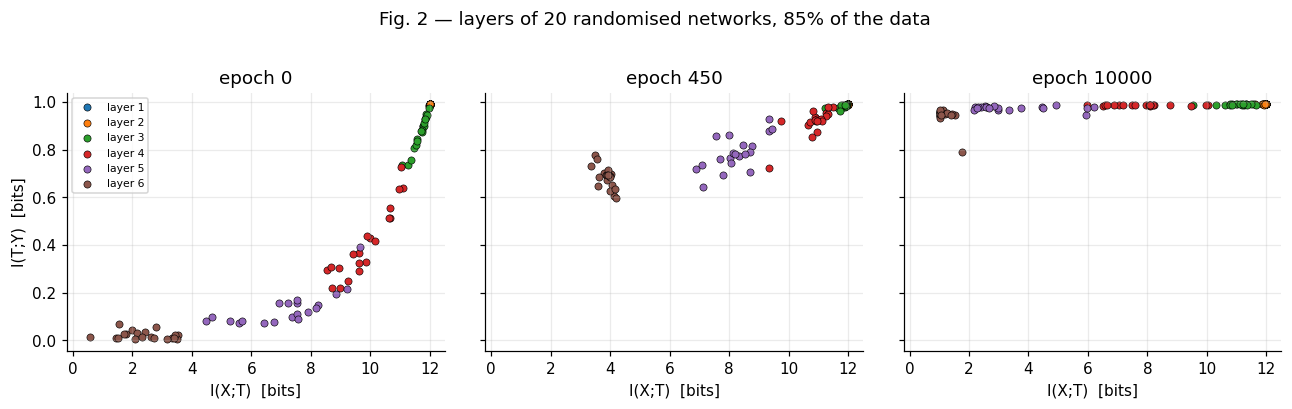

In [8]:
def plot_snapshots(res, title=""):
    ep = res["epochs"]; E = ep[-1]
    picks = [0, int(ep[np.argmin(np.abs(ep - 0.045 * E))]), E]
    L = res["IX"].shape[2]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
    for a, e in zip(axes, picks):
        s = int(np.where(ep == e)[0][0])
        for l in range(L):
            a.scatter(res["IX"][s, :, l], res["IY"][s, :, l], s=22, color=LAYER_COLORS[l], edgecolor="k", lw=0.4,
                      label=f"layer {l+1}" if e == 0 else None)
        a.set(xlim=(-0.2, 12.5), xlabel="I(X;T)  [bits]", title=f"epoch {e}")
    axes[0].set_ylabel("I(T;Y)  [bits]"); axes[0].legend(fontsize=7, loc="upper left")
    fig.suptitle(title, y=1.02); plt.tight_layout(); return fig

fig = plot_snapshots(MAIN, f"Fig. 2 — layers of {N_NETS} randomised networks, 85% of the data"); savefig(fig, "fig2_snapshots"); plt.show()

## 6. The two SGD phases: drift and diffusion (Figures 4 and 3)

**Figure 4.** For each layer we plot the L2 norm of the *mean* of the stochastic gradient across mini-batches (solid) and the norm of its *standard deviation* (dotted), normalised by the layer's weight norm. The paper finds an early **drift** phase (mean ≫ std, high gradient SNR) followed by a **diffusion** phase (std ≫ mean, SNR < 1), with the transition at ≈350 epochs for their setup. We define the transition as the first epoch *after the SNR peak* where the (geometric-mean over layers) SNR drops below 1; if the SNR never exceeds 1 there is no drift phase and the notebook warns you.

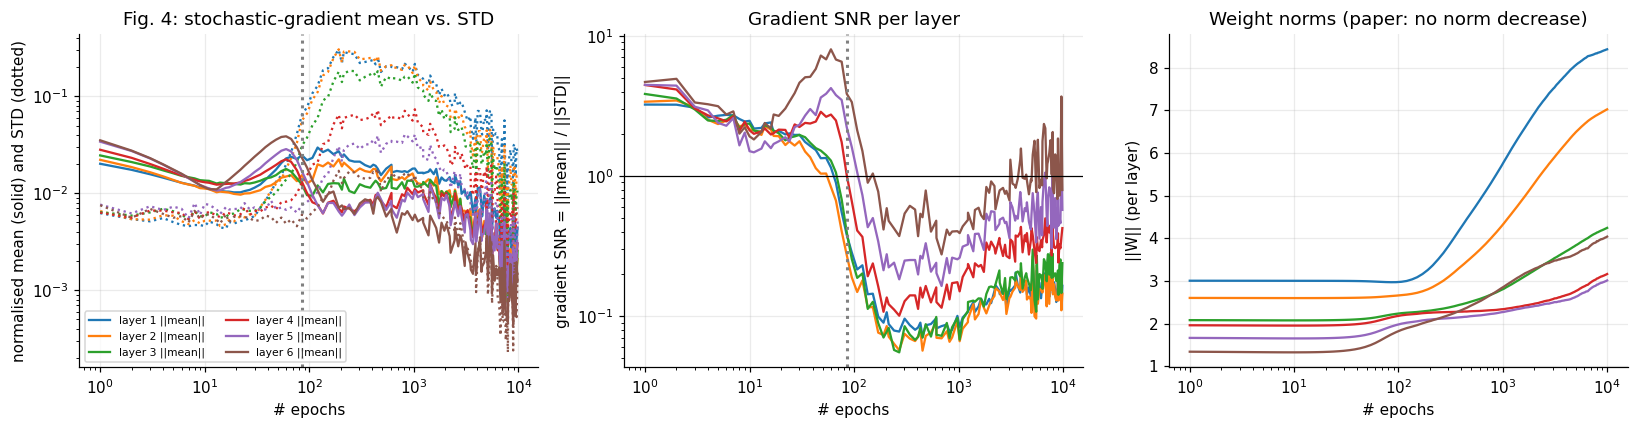

initial gradient SNR (geo-mean over layers) = 3.97, peak = 3.97
drift -> diffusion transition (SNR=1) at epoch 84 of 10000  => 99% of all epochs are spent in the diffusion/compression phase


In [9]:
def transition_epoch(res):
    """Drift->diffusion transition: first epoch AFTER the SNR peak where the (geometric-mean over layers)
    gradient SNR drops below 1. Returns (epoch, snr_curve, has_drift_phase)."""
    g, ep = res["grad"], res["epochs"]
    gsnr = np.exp(np.nanmean(np.log(g["mean"] / g["std"]), axis=1))          # [S]
    pk = int(np.nanargmax(gsnr[: len(ep) // 2]))
    if gsnr[pk] < 1:                                   # SNR never above 1: there is no drift phase to speak of
        return int(ep[pk]), gsnr, False
    below = np.where((gsnr < 1) & (np.arange(len(ep)) > pk))[0]
    return (int(ep[below[0]]) if len(below) else int(ep[pk])), gsnr, True

T_EPOCH, GSNR, HAS_DRIFT = transition_epoch(MAIN)
g, ep = MAIN["grad"], MAIN["epochs"]; L = len(WIDTHS) - 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for l in range(L):
    ax[0].loglog(ep + 1, g["mean"][:, l], color=LAYER_COLORS[l], label=f"layer {l+1} ||mean||")
    ax[0].loglog(ep + 1, g["std"][:, l], color=LAYER_COLORS[l], ls=":")
    ax[1].semilogx(ep + 1, g["mean"][:, l] / g["std"][:, l], color=LAYER_COLORS[l])
    ax[2].semilogx(ep + 1, g["wnorm"][:, l], color=LAYER_COLORS[l])
for a in ax[:2]: a.axvline(T_EPOCH + 1, color="grey", ls=":", lw=2)
ax[1].axhline(1, color="k", lw=0.8)
ax[0].set(xlabel="# epochs", ylabel="normalised mean (solid) and STD (dotted)", title="Fig. 4: stochastic-gradient mean vs. STD")
ax[1].set(xlabel="# epochs", ylabel="gradient SNR = ||mean|| / ||STD||", title="Gradient SNR per layer"); ax[1].set_yscale("log")
ax[2].set(xlabel="# epochs", ylabel="||W|| (per layer)", title="Weight norms (paper: no norm decrease)")
ax[0].legend(fontsize=7, ncol=2); plt.tight_layout(); savefig(fig, "fig4_gradient_snr"); plt.show()
print(f"initial gradient SNR (geo-mean over layers) = {GSNR[0]:.2f}, peak = {np.nanmax(GSNR[:len(GSNR)//2]):.2f}")
print(f"drift -> diffusion transition (SNR=1) at epoch {T_EPOCH} of {EPOCHS}  "
      f"=> {(EPOCHS - T_EPOCH) / EPOCHS:.0%} of all epochs are spent in the diffusion/compression phase")
if not HAS_DRIFT:
    print("WARNING: gradient SNR never exceeds 1 -> no real drift phase; increase BATCH and/or decrease LR.")

**Figure 3.** Average layer trajectories (colour = epoch) for three training-set sizes. The thin grey fans connect the layers at each epoch (the "information path"). Green marks the layers at the drift→diffusion transition found above: before it $I(T;Y)$ rises (**ERM / fitting**), after it the paths bend to the left (**compression**, $I(X;T)$ decreases).

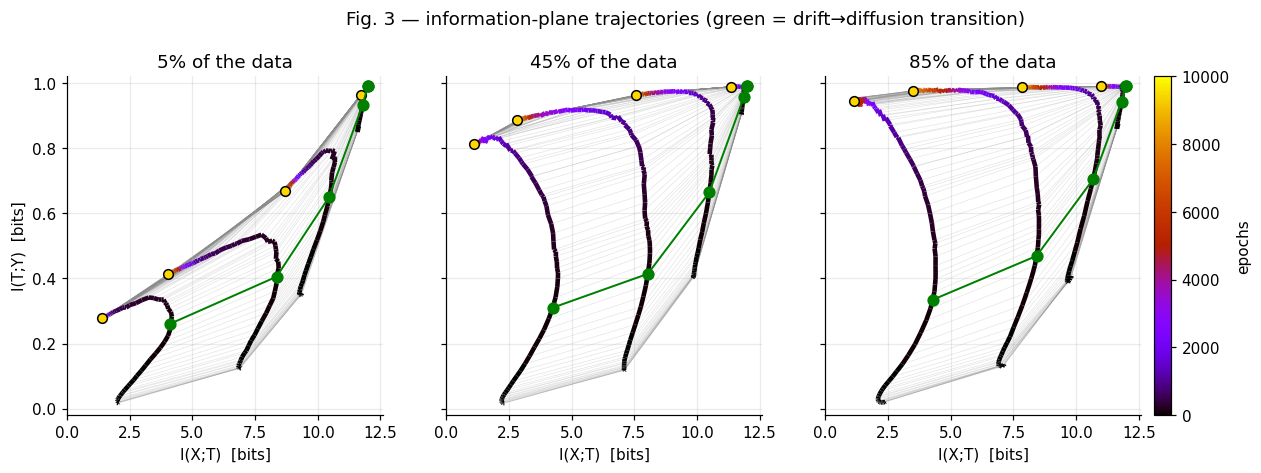

In [10]:
def plot_paths(ax, res, ep_trans=None, cmap="gnuplot", xlim=(0, 12.6), ylim=None):
    ep = res["epochs"]; mIX, mIY = res["IX"].mean(1), res["IY"].mean(1); L = mIX.shape[1]
    norm = colors.Normalize(0, ep[-1])
    for s in range(len(ep)):
        ax.plot(mIX[s], mIY[s], color="0.55", lw=0.4, alpha=0.25, zorder=1)
    for l in range(L):
        pts = np.column_stack([mIX[:, l], mIY[:, l]])
        lc = LineCollection(np.stack([pts[:-1], pts[1:]], 1), cmap=cmap, norm=norm, linewidths=3, zorder=2)
        lc.set_array(ep[:-1]); ax.add_collection(lc)
    ax.scatter(mIX[-1], mIY[-1], s=40, color="gold", edgecolor="k", zorder=4)
    if ep_trans is not None:
        s = int(np.argmin(np.abs(ep - ep_trans)))
        ax.plot(mIX[s], mIY[s], "-o", color="green", ms=7, lw=1.3, zorder=5)
    ax.set_xlim(*xlim)
    if ylim: ax.set_ylim(*ylim)
    return norm

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, frac in zip(axes, [0.05, 0.45, 0.85]):
    norm = plot_paths(a, SWEEP[frac], T_EPOCH, ylim=(-0.02, 1.02))
    a.set(xlabel="I(X;T)  [bits]", title=f"{int(frac*100)}% of the data")
axes[0].set_ylabel("I(T;Y)  [bits]")
sm = plt.cm.ScalarMappable(norm=norm, cmap="gnuplot"); fig.colorbar(sm, ax=axes, label="epochs", pad=0.01)
fig.suptitle("Fig. 3 — information-plane trajectories (green = drift→diffusion transition)", y=1.03)
savefig(fig, "fig3_paths"); plt.show()

## 7. Figure 7 — converged layers vs. training-set size

Each line connects the six layers of the converged networks (averaged over the random initialisations) for one training-set size. The paper reports that with more data the deeper layers move **up** (more label information, closer to the IB bound) and the middle layers shift to higher $I(X;T)$.

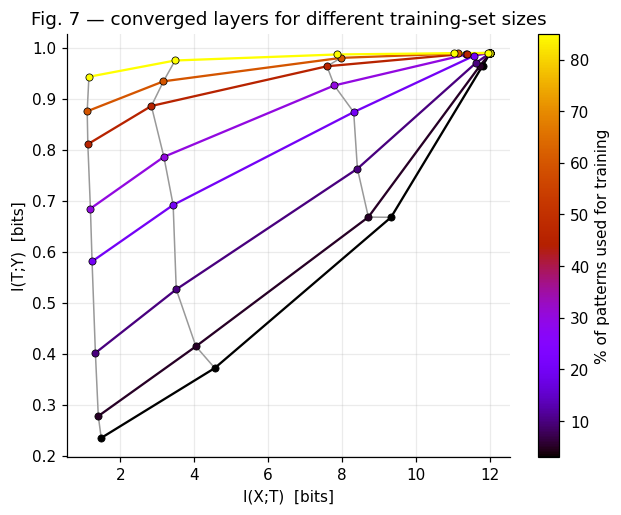

final I(T_out;Y) of the last layer by training fraction: {'3%': 0.234, '5%': 0.277, '10%': 0.401, '20%': 0.581, '30%': 0.685, '45%': 0.811, '60%': 0.876, '85%': 0.943}


In [11]:
fig, ax = plt.subplots(figsize=(6.5, 5))
fr = sorted(SWEEP); cm_ = plt.cm.gnuplot; nrm = colors.Normalize(min(fr) * 100, max(fr) * 100)
FIN = np.array([[SWEEP[f]["IX"][-1].mean(0), SWEEP[f]["IY"][-1].mean(0)] for f in fr])   # [F, 2, L]
for l in range(FIN.shape[2]):
    ax.plot(FIN[:, 0, l], FIN[:, 1, l], color="0.6", lw=1, zorder=1)                      # same layer, growing data
for i, f in enumerate(fr):
    ax.plot(FIN[i, 0], FIN[i, 1], "-", color=cm_(nrm(f * 100)), lw=1.5, zorder=2)
    ax.scatter(FIN[i, 0], FIN[i, 1], s=22, color=cm_(nrm(f * 100)), edgecolor="k", lw=0.5, zorder=3)
ax.set(xlabel="I(X;T)  [bits]", ylabel="I(T;Y)  [bits]", title="Fig. 7 — converged layers for different training-set sizes")
fig.colorbar(plt.cm.ScalarMappable(norm=nrm, cmap=cm_), ax=ax, label="% of patterns used for training")
savefig(fig, "fig7_training_size"); plt.show()
print("final I(T_out;Y) of the last layer by training fraction:",
      {f"{int(f*100)}%": round(float(SWEEP[f]['IY'][-1][:, -1].mean()), 3) for f in fr})

## 8. Figure 6 — are the converged layers on the Information-Bottleneck bound?

**IB curve.** For the known $P(X,Y)$ we solve the IB problem $\min_{p(t|x)} I(X;T)-\beta I(T;Y)$ with the three self-consistent equations (paper Eq. 9)

$$p(t|x)=\frac{p(t)}{Z(x;\beta)}e^{-\beta D_{KL}[p(y|x)\,\|\,p(y|t)]},\qquad p(t)=\sum_x p(t|x)p(x),\qquad p(y|t)=\sum_x p(y|x)p(x|t),$$

iterated to a fixed point while sweeping $\beta$ upward (deterministic annealing). Since $p(y|x)$ only depends on the class of $x$, we iterate over the ≤64 distinct values of $p(y|x)$ — this gives exactly the same $(I(X;T), I(T;Y))$ curve.

**β\* of a layer (Eq. 12).** Using the layer's own decoder $p_i(y|t)$ we build the optimal IB encoder $p^{IB}_\beta(t|x)\propto p_i(t)\exp(-\beta D_{KL}[p(y|x)\|p_i(y|t)])$ and pick $\beta^*_i=\arg\min_\beta \mathbb{E}_x D_{KL}[p_i(t|x)\,\|\,p^{IB}_\beta(t|x)]$. As the layer encoder is deterministic, the KL is just $-\log p^{IB}_\beta(t_i(x)|x)$.

In [12]:
LN2 = np.log(2)

def ib_curve(py1, betas, n_clusters=64, n_iter=1500, tol=1e-9, noise=2e-2, seed=0):
    """IB curve by iterating Eq. (9) with annealing over increasing beta. Returns IX, IY in bits."""
    qv, cnt = np.unique(np.round(py1, 10), return_counts=True)
    px = cnt / cnt.sum(); q = np.clip(qv, 1e-12, 1 - 1e-12); K = len(q); T = n_clusters
    rng = np.random.default_rng(seed)
    ptx = np.full((K, T), 1.0 / T); IXs, IYs = [], []
    HY = H2(py1.mean()) * LN2
    for beta in betas:
        ptx = ptx * (1 + noise * rng.standard_normal((K, T))); ptx /= ptx.sum(1, keepdims=True)
        for _ in range(n_iter):
            pt = px @ ptx
            r = np.clip(((px * q) @ ptx) / np.maximum(pt, 1e-300), 1e-12, 1 - 1e-12)         # p(y=1|t)
            D = q[:, None] * np.log(q[:, None] / r[None]) + (1 - q)[:, None] * np.log((1 - q)[:, None] / (1 - r)[None])
            lg = np.log(np.maximum(pt, 1e-300))[None] - beta * D
            lg -= lg.max(1, keepdims=True); new = np.exp(lg); new /= new.sum(1, keepdims=True)
            done = np.abs(new - ptx).max() < tol; ptx = new
            if done: break
        pt = px @ ptx; r = np.clip(((px * q) @ ptx) / np.maximum(pt, 1e-300), 1e-12, 1 - 1e-12)
        IX = (px[:, None] * ptx * np.log(np.maximum(ptx, 1e-300) / np.maximum(pt, 1e-300)[None])).sum()
        IY = HY - (pt * (-(r * np.log(r) + (1 - r) * np.log(1 - r)))).sum()
        IXs.append(IX / LN2); IYs.append(IY / LN2)
    IXs, IYs = np.array(IXs), np.array(IYs)
    return IXs, np.maximum.accumulate(IYs)                                                  # enforce monotone envelope

def estimate_beta(codes, py1, betas):
    """Eq. (12) for one layer of one net. codes: [4096] code index t(x). Returns beta*, loss curve."""
    K = codes.max() + 1; cnt = np.bincount(codes, minlength=K); pt = cnt / len(codes)
    r = np.clip(np.bincount(codes, weights=py1, minlength=K) / cnt, 1e-9, 1 - 1e-9)
    qv, qi = np.unique(np.round(py1, 10), return_inverse=True); qi = qi.ravel(); qv = np.clip(qv, 1e-9, 1 - 1e-9)
    D = qv[:, None] * np.log(qv[:, None] / r[None]) + (1 - qv)[:, None] * np.log((1 - qv)[:, None] / (1 - r)[None])
    lpt = np.log(pt); loss = []
    for b in betas:
        lg = lpt[None] - b * D
        lse = np.logaddexp.reduce(lg, axis=1)
        loss.append(-(lg[qi, codes] - lse[qi]).mean())
    loss = np.array(loss); return betas[int(np.argmin(loss))], loss

t0 = time.time()
IB_BETAS = np.geomspace(0.5, 3000, 160)
IB_IX, IB_IY = cached("ib_curve", lambda: ib_curve(PY1, IB_BETAS))
print(f"IB curve computed in {time.time()-t0:.1f}s: I(X;T) in [{IB_IX.min():.2f}, {IB_IX.max():.2f}] bits, "
      f"I(T;Y) up to {IB_IY.max():.4f} (I(X;Y) = {RULE['IXY']:.4f})")

IB curve computed in 0.2s: I(X;T) in [0.00, 1.53] bits, I(T;Y) up to 0.9900 (I(X;Y) = 0.9900)


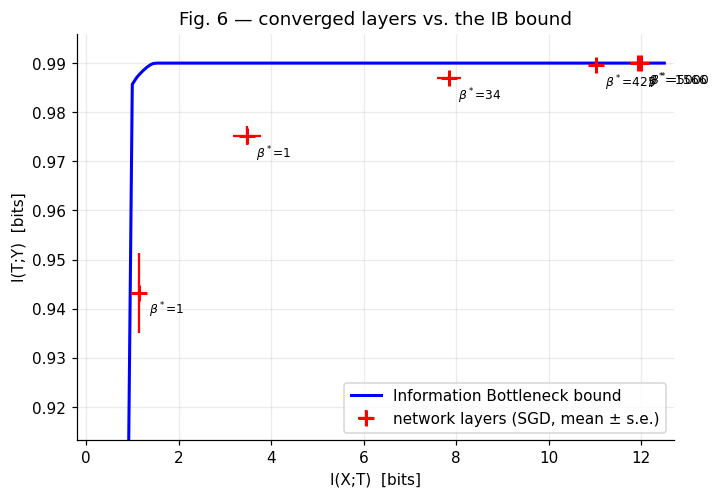

layer width   I(X;T)   I(T;Y)  IB I(T;Y) @ same I(X;T)  vert. gap  excess I(X;T)  beta* (median)
    1    10    12.00    0.990                    0.990     -0.000       10.55 b      5000.0 (grid edge!)
    2     7    11.94    0.990                    0.990      0.000       10.50 b      1565.9
    3     5    11.02    0.990                    0.990      0.000        9.66 b       424.7
    4     4     7.85    0.987                    0.990      0.003        6.76 b        34.3
    5     3     3.48    0.975                    0.990      0.015        2.50 b         1.5
    6     2     1.15    0.943                    0.988      0.044        0.20 b         1.1
vert. gap = how far below the IB curve (same I(X;T));  excess I(X;T) = bits more than the IB-optimal representation with the same I(T;Y).
NOTE: the IB curve is flat at I(X;Y) for I(X;T) > ~1.5 bits, so wide near-lossless layers have a ~0 vertical gap but a large horizontal one.
beta* should decrease with depth (paper):  True


In [13]:
BETA_GRID = np.geomspace(0.05, 5000, 120)
def layers_vs_ib():
    L = len(WIDTHS) - 1; betas = np.zeros((N_NETS, L))
    for n in tqdm(range(N_NETS), desc="beta*", leave=False):
        for l in range(L):
            betas[n, l], _ = estimate_beta(MAIN["codes"][n][l], PY1, BETA_GRID)
    return betas
BETAS_STAR = cached("beta_star", layers_vs_ib)

IXf, IYf = MAIN["IX"][-1], MAIN["IY"][-1]                                  # [N, L] final snapshot
mx, my = IXf.mean(0), IYf.mean(0); sx, sy = IXf.std(0, ddof=1) / np.sqrt(N_NETS), IYf.std(0, ddof=1) / np.sqrt(N_NETS)
# extend the curve with its plateau up to 12 bits and interpolate to measure how far each layer is from the bound
cx = np.r_[IB_IX, 12.5]; cy = np.r_[IB_IY, IB_IY[-1]]
gap = np.interp(mx, cx, cy) - my                                           # vertical distance to the bound
def min_IX_for(y):                                                           # smallest I(X;T) on the IB curve with I(T;Y) >= y
    i = int(np.searchsorted(IB_IY, y - 1e-4))
    if i >= len(IB_IY): return np.nan
    if i == 0: return float(IB_IX[0])
    w = (y - IB_IY[i - 1]) / max(IB_IY[i] - IB_IY[i - 1], 1e-12)
    return float(IB_IX[i - 1] + np.clip(w, 0, 1) * (IB_IX[i] - IB_IX[i - 1]))
xgap = mx - np.array([min_IX_for(y) for y in my])                            # horizontal distance ("redundant bits")

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(cx, cy, color="b", lw=2, label="Information Bottleneck bound")
ax.errorbar(mx, my, xerr=sx, yerr=sy, fmt="r+", ms=10, mew=2, capsize=0, label="network layers (SGD, mean ± s.e.)")
for l in range(len(mx)):
    ax.annotate(rf"$\beta^*$={np.median(BETAS_STAR[:, l]):.0f}", (mx[l], my[l]), textcoords="offset points", xytext=(6, -14), fontsize=8)
ax.set(xlabel="I(X;T)  [bits]", ylabel="I(T;Y)  [bits]", xlim=(-0.2, 12.7), ylim=(min(my) - 0.03, RULE["IXY"] + 0.006),
       title="Fig. 6 — converged layers vs. the IB bound")
ax.legend(loc="lower right"); savefig(fig, "fig6_ib_bound"); plt.show()

print(f"{'layer':>5} {'width':>5} {'I(X;T)':>8} {'I(T;Y)':>8} {'IB I(T;Y) @ same I(X;T)':>24} {'vert. gap':>10} {'excess I(X;T)':>14} {'beta* (median)':>15}")
for l in range(len(mx)):
    b = np.median(BETAS_STAR[:, l]); flag = " (grid edge!)" if (b <= BETA_GRID[0] * 1.01 or b >= BETA_GRID[-1] * 0.99) else ""
    print(f"{l+1:>5} {WIDTHS[l+1]:>5} {mx[l]:>8.2f} {my[l]:>8.3f} {np.interp(mx[l], cx, cy):>24.3f} {gap[l]:>10.3f} {xgap[l]:>11.2f} b {b:>11.1f}{flag}")
print("vert. gap = how far below the IB curve (same I(X;T));  excess I(X;T) = bits more than the IB-optimal representation with the same I(T;Y).")
print("NOTE: the IB curve is flat at I(X;Y) for I(X;T) > ~1.5 bits, so wide near-lossless layers have a ~0 vertical gap but a large horizontal one.")
print("beta* should decrease with depth (paper): ", bool(np.all(np.diff(np.median(BETAS_STAR, 0)) <= 1e-9)))

## 9. Figure 5 — what do the hidden layers buy us?

We train networks with 1 … 6 hidden layers (widths 12, 10, 8, 6, 4, 2 truncated to the first *k*, then the 2-unit output layer, as in the paper's caption) on 80 % of the patterns and compare the information paths and — most importantly — **how many epochs are needed** for the output layer to carry the relevant information. The paper's claim (§3.6–3.7): more hidden layers ⇒ dramatically fewer epochs, because each layer only has to compress a little relative to the previous one (relaxation time $\sim\exp(\Delta I_X)$, and $\exp(\sum_k\Delta I^k)\gg\sum_k\exp(\Delta I^k)$).

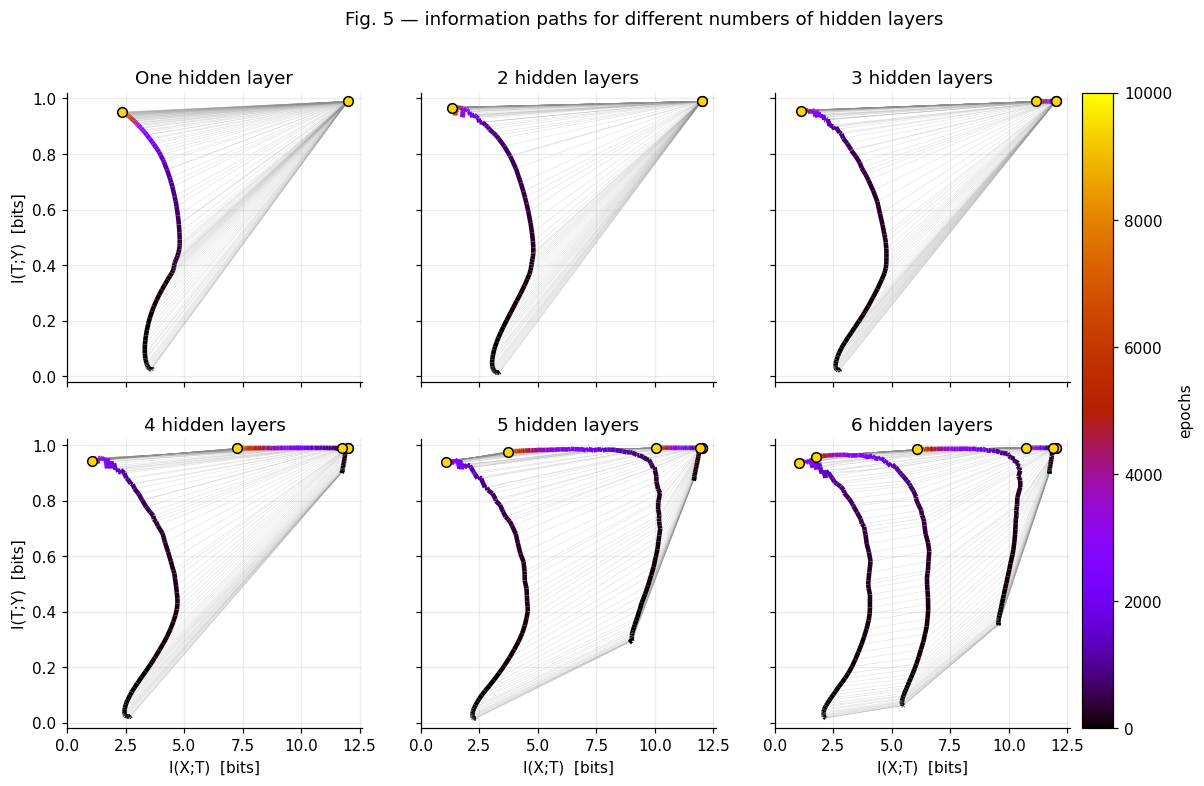

In [14]:
HIDDEN = [12, 10, 8, 6, 4, 2]
def run_depth():
    out = {}
    for k in range(1, 7):
        t0 = time.time()
        out[k] = train_ensemble([12] + HIDDEN[:k] + [2], PY1, 0.80, N_NETS, EPOCHS, seed=SEED + 100 * k, desc=f"{k} hidden")
        print(f"  {k} hidden layer(s): widths {out[k]['widths']}  ({time.time()-t0:.0f}s)")
    return out
DEPTH = cached("depth", run_depth)

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True, sharey=True)
for k, a in zip(range(1, 7), axes.ravel()):
    norm = plot_paths(a, DEPTH[k], None, xlim=(0, 12.6), ylim=(-0.02, 1.02))
    a.set_title(f"{'One' if k==1 else k} hidden layer{'s' if k>1 else ''}")
for a in axes[1]: a.set_xlabel("I(X;T)  [bits]")
for a in axes[:, 0]: a.set_ylabel("I(T;Y)  [bits]")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="gnuplot"), ax=axes, label="epochs", pad=0.01)
fig.suptitle("Fig. 5 — information paths for different numbers of hidden layers", y=0.98)
savefig(fig, "fig5_depth_paths"); plt.show()

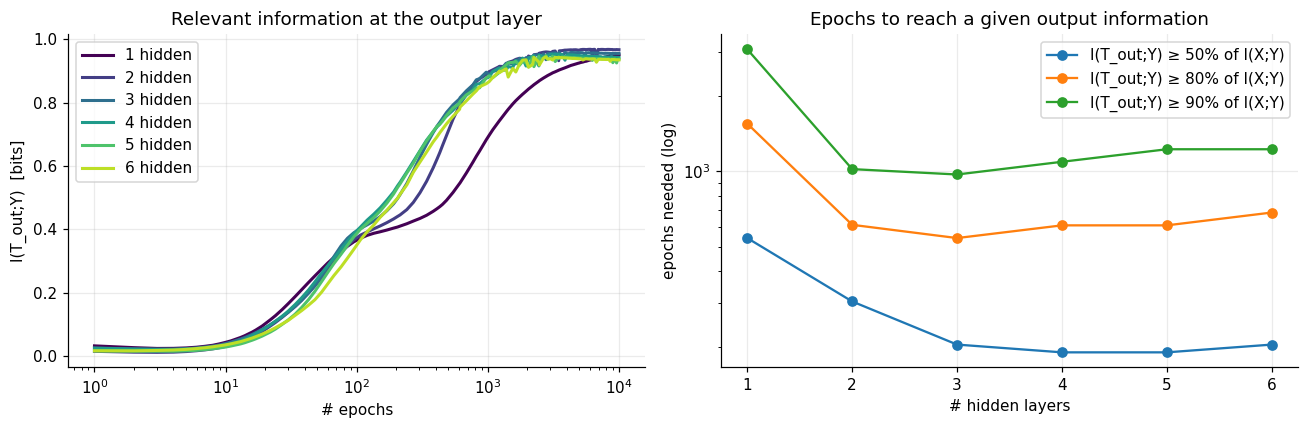

epochs until the output layer reaches x% of I(X;Y)  (None = not reached within the budget):
 #hidden       50%       80%       90%
       1       542      1548      3061
       2       303       612      1020
       3       204       542       971
       4       190       609      1091
       5       190       609      1224
       6       204       685      1224


In [15]:
IXY = RULE["IXY"]; thr_list = [0.5, 0.8, 0.9]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cmap_d = plt.cm.viridis(np.linspace(0, 0.9, 6)); rows = []
for k in range(1, 7):
    ep = DEPTH[k]["epochs"]; iy_out = DEPTH[k]["IY"][:, :, -1].mean(1)
    ax[0].semilogx(ep + 1, iy_out, color=cmap_d[k - 1], lw=2, label=f"{k} hidden")
    row = [k]
    for thr in thr_list:
        hit = np.where(iy_out >= thr * IXY)[0]; row.append(int(ep[hit[0]]) if len(hit) else None)
    rows.append(row)
ax[0].set(xlabel="# epochs", ylabel="I(T_out;Y)  [bits]", title="Relevant information at the output layer"); ax[0].legend()
for j, thr in enumerate(thr_list):
    ks = [r[0] for r in rows if r[j + 1] is not None]; ys = [r[j + 1] for r in rows if r[j + 1] is not None]
    ax[1].semilogy(ks, ys, "o-", label=f"I(T_out;Y) ≥ {int(thr*100)}% of I(X;Y)")
ax[1].set(xlabel="# hidden layers", ylabel="epochs needed (log)", title="Epochs to reach a given output information"); ax[1].legend()
plt.tight_layout(); savefig(fig, "fig5b_epochs_vs_depth"); plt.show()
print("epochs until the output layer reaches x% of I(X;Y)  (None = not reached within the budget):")
print(f"{'#hidden':>8}" + "".join(f"{int(t*100):>9}%" for t in thr_list))
for r in rows: print(f"{r[0]:>8}" + "".join(f"{str(v):>10}" for v in r[1:]))

## 10. Figure 8 — a different rule and architecture (paper §4, question 1)

To test generality the paper repeats the analysis for a **non-symmetric committee machine**. We use a teacher committee of $K=5$ random perceptrons on the (bipolar) inputs, $y=\mathrm{sign}\big(\sum_k \mathrm{sign}(w_k\!\cdot\!x)\big)$, softened with a sigmoid of gain $\gamma$ chosen so that $I(X;Y)=0.99$ bits. The student is a different network, `12-8-5-3-2`.

committee rule: P(y=1) = 0.500, I(X;Y) = 0.990 bits


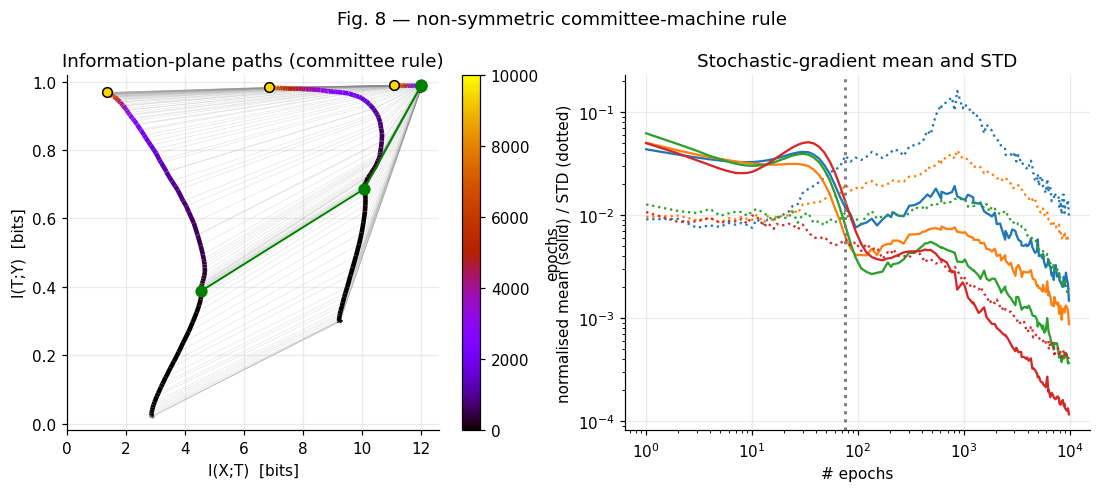

drift->diffusion transition at epoch 75


In [16]:
def make_committee_rule(seed=1, K=5, target_IXY=0.99):
    rng = np.random.default_rng(seed)
    S = np.sign((2 * X_ALL - 1) @ rng.normal(size=(12, K))).sum(1)         # odd integer vote count, antisymmetric in x
    lo, hi = 0.01, 100.0
    for _ in range(80):
        g = np.sqrt(lo * hi)
        lo, hi = (g, hi) if mutual_info_xy(expit(g * S)) < target_IXY else (lo, g)
    return expit(np.sqrt(lo * hi) * S)

PY1_CM = make_committee_rule()
print(f"committee rule: P(y=1) = {PY1_CM.mean():.3f}, I(X;Y) = {mutual_info_xy(PY1_CM):.3f} bits")
CM = cached("committee", lambda: train_ensemble([12, 8, 5, 3, 2], PY1_CM, 0.85, N_NETS, EPOCHS, track_grad=True, seed=SEED + 7, desc="committee"))
T_CM, _, HAS_DRIFT_CM = transition_epoch(CM)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
norm = plot_paths(ax[0], CM, T_CM, ylim=(-0.02, 1.02)); ax[0].set(xlabel="I(X;T)  [bits]", ylabel="I(T;Y)  [bits]", title="Information-plane paths (committee rule)")
g, ep = CM["grad"], CM["epochs"]
for l in range(g["mean"].shape[1]):
    ax[1].loglog(ep + 1, g["mean"][:, l], color=LAYER_COLORS[l]); ax[1].loglog(ep + 1, g["std"][:, l], color=LAYER_COLORS[l], ls=":")
ax[1].axvline(T_CM + 1, color="grey", ls=":", lw=2)
ax[1].set(xlabel="# epochs", ylabel="normalised mean (solid) / STD (dotted)", title="Stochastic-gradient mean and STD")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="gnuplot"), ax=ax[0], label="epochs")
fig.suptitle("Fig. 8 — non-symmetric committee-machine rule", y=1.02); savefig(fig, "fig8_committee"); plt.show()
print(f"drift->diffusion transition at epoch {T_CM}")

## 11. Extra: does the compression phase depend on the activation function?

The paper's experiments use tanh (a double-saturating non-linearity). Follow-up work (e.g. Saxe et al., ICLR 2018, *On the Information Bottleneck Theory of Deep Learning*) argued that the compression seen with binned MI estimates is tied to saturating activations and is **not** universal. This is a cheap, informative ablation: we train the same network with **ReLU** units (bins span $[0,\max]$ of each layer, same number of networks as the tanh run) and compare how $I(X;T)$ evolves. Besides the curves we print, per layer, how far $I(X;T)$ falls from its peak to the end of training (mean ± s.e. over networks), so the claim "ReLU compresses less / more" is backed by numbers.

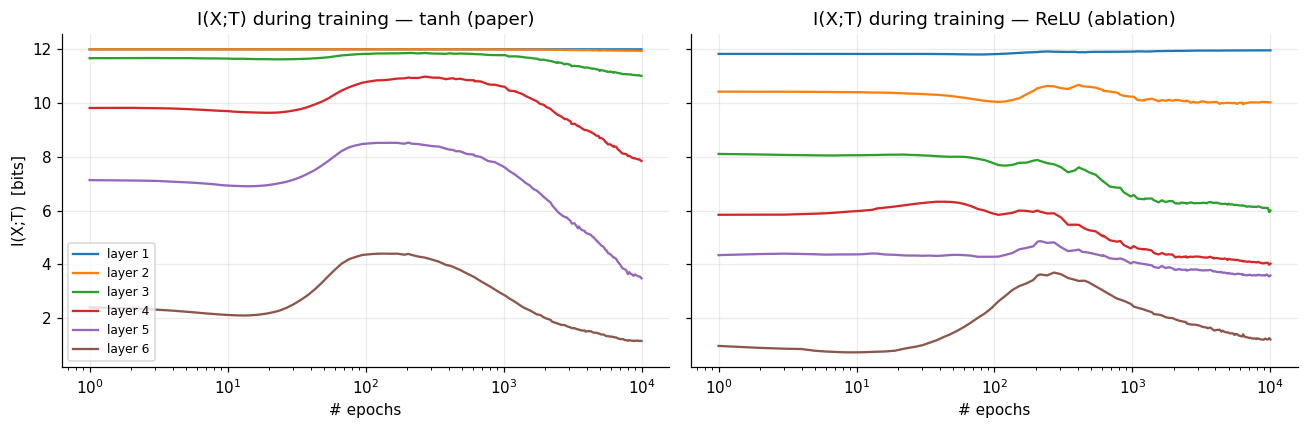

drop of I(X;T) from its peak to the end of training, mean ± s.e. over networks (bits; negative = compression)
 layer  width         tanh (n=20)         ReLU (n=20)
     1     10       -0.00 ± 0.00       -0.02 ± 0.01
     2      7       -0.06 ± 0.02       -1.05 ± 0.16
     3      5       -0.90 ± 0.10       -3.17 ± 0.34
     4      4       -3.28 ± 0.25       -3.17 ± 0.24
     5      3       -5.35 ± 0.39       -2.38 ± 0.24
     6      2       -3.40 ± 0.05       -3.16 ± 0.09
layers that compress (drop > 2 s.e. and at least 0.5 bit): tanh 4/6, ReLU 5/6


In [17]:
N_RELU = N_NETS                           # same number of networks as the tanh run (the first version used only 10)
RELU = cached("relu", lambda: train_ensemble(WIDTHS, PY1, 0.85, N_RELU, EPOCHS, act="relu", seed=SEED + 9, desc="relu"))

MIN_DROP = 0.5      # a layer counts as compressing if its drop exceeds 2 s.e. AND is at least this many bits

def peak_to_end(IX):
    """IX: [snapshots, nets, layers] -> mean and s.e. over nets of (final - peak) I(X;T) per layer, in bits.
    Negative = the layer compresses (loses information about X) after its peak."""
    d = IX[-1] - IX.max(0)
    return d.mean(0), d.std(0, ddof=1) / np.sqrt(d.shape[0])

def n_compressing(d, se):
    return int(((d < -2 * se) & (d <= -MIN_DROP)).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, res, name in [(ax[0], MAIN, "tanh (paper)"), (ax[1], RELU, "ReLU (ablation)")]:
    for l in range(res["IX"].shape[2]):
        a.semilogx(res["epochs"] + 1, res["IX"][:, :, l].mean(1), color=LAYER_COLORS[l], label=f"layer {l+1}")
    a.set(xlabel="# epochs", title=f"I(X;T) during training — {name}")
ax[0].set_ylabel("I(X;T)  [bits]"); ax[0].legend(fontsize=8)
plt.tight_layout(); savefig(fig, "extra_relu_ablation"); plt.show()

(d_t, se_t), (d_r, se_r) = peak_to_end(MAIN["IX"]), peak_to_end(RELU["IX"])
TANH_NCOMP, RELU_NCOMP = n_compressing(d_t, se_t), n_compressing(d_r, se_r)
print(f"drop of I(X;T) from its peak to the end of training, mean ± s.e. over networks (bits; negative = compression)")
print(f"{'layer':>6}{'width':>7}{'tanh (n=' + str(N_NETS) + ')':>20}{'ReLU (n=' + str(N_RELU) + ')':>20}")
for l in range(len(d_t)):
    print(f"{l+1:>6}{WIDTHS[l+1]:>7}{d_t[l]:>+12.2f} ± {se_t[l]:.2f}{d_r[l]:>+12.2f} ± {se_r[l]:.2f}")
print(f"layers that compress (drop > 2 s.e. and at least {MIN_DROP} bit): tanh {TANH_NCOMP}/{len(d_t)}, ReLU {RELU_NCOMP}/{len(d_r)}")


## 12. Extra: how sensitive is the compression result to the number of bins?

All mutual-information values in this notebook come from **binning** each layer's activations (30 bins, as in the paper). The binned estimate of $I(X;T)=H(T)$ is exactly the entropy of the *discretised* layer, so the bin count matters: fewer bins merge more inputs into the same code (lower $I(X;T)$), more bins separate them (higher, capped at $\log_2 4096 = 12$ bits).

We retrain the 85 % main run once (same seed and settings as §5, so the 30-bin curve must coincide with `MAIN`; this is printed as a sanity check) and, at every snapshot, compute $I(X;T)$ and $I(T;Y)$ with **10, 30 and 100** bins. We then ask the same question as in claim (ii): after its peak, does each layer's $I(X;T)$ fall significantly (by more than 2 s.e. over the networks and by at least 0.5 bit)?

sanity: max |I(X;T)_30bins(this run) - I(X;T)(MAIN)| = 0.00e+00 bits (should be ~0)


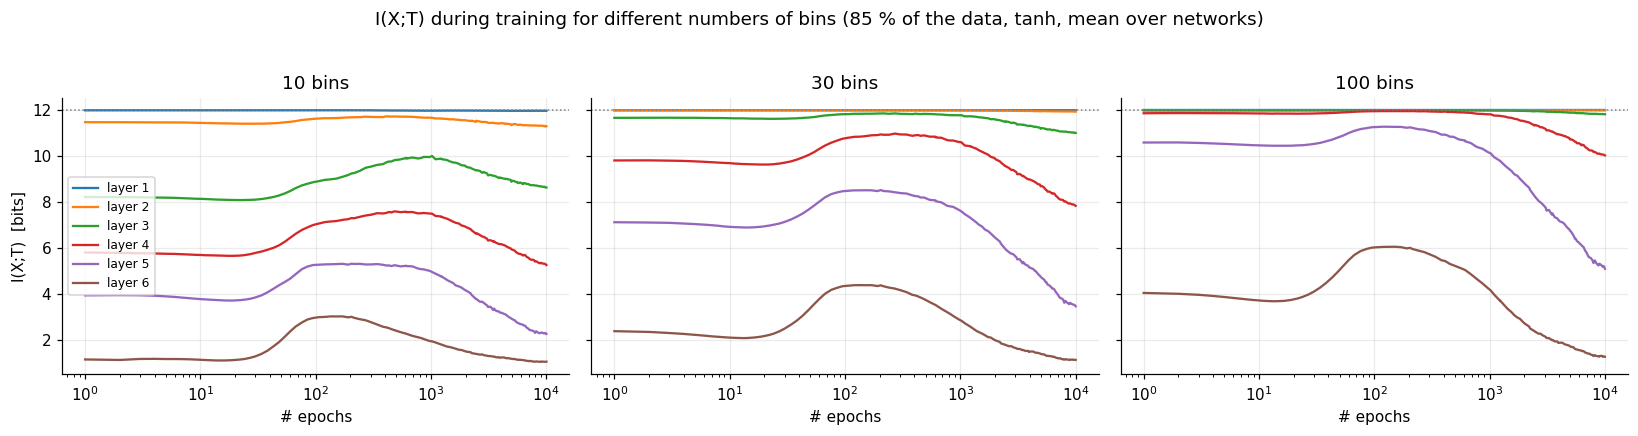

drop of I(X;T) from its peak to the end of training, mean ± s.e. over networks (bits; negative = compression)
 bins |  layer 1 (w=10)  layer 2 (w= 7)  layer 3 (w= 5)  layer 4 (w= 4)  layer 5 (w= 3)  layer 6 (w= 2) | compressing layers
   10 |   -0.02 ± 0.00     -0.55 ± 0.09     -1.60 ± 0.14     -2.56 ± 0.24     -3.27 ± 0.26     -2.11 ± 0.03   | 5/6
   30 |   -0.00 ± 0.00     -0.06 ± 0.02     -0.90 ± 0.10     -3.28 ± 0.25     -5.35 ± 0.39     -3.40 ± 0.05   | 4/6
  100 |   +0.00 ± 0.00     -0.00 ± 0.00     -0.17 ± 0.04     -1.94 ± 0.20     -6.38 ± 0.39     -4.95 ± 0.09   | 3/6

final I(X;T) per layer (bits):
   10 bins:  11.98   11.31    8.64    5.27    2.28    1.07
   30 bins:  12.00   11.94   11.02    7.85    3.48    1.15
  100 bins:  12.00   12.00   11.83   10.04    5.11    1.29


In [18]:
BIN_LIST = [10, 30, 100]                      # the paper uses 30
BINS = cached("bins", lambda: train_ensemble(WIDTHS, PY1, 0.85, N_NETS, EPOCHS, seed=SEED + int(0.85 * 1000),
                                              nbins_list=BIN_LIST, desc="bin sensitivity"))
ep, Lh = BINS["epochs"], len(WIDTHS) - 1
if BINS["IX"].shape == MAIN["IX"].shape:
    print(f"sanity: max |I(X;T)_30bins(this run) - I(X;T)(MAIN)| = {np.abs(BINS['IX'] - MAIN['IX']).max():.2e} bits (should be ~0)")

fig, axes = plt.subplots(1, len(BIN_LIST), figsize=(5 * len(BIN_LIST), 3.8), sharey=True)
BIN_NCOMP, rows_b = {}, []
for a, nb in zip(axes, BIN_LIST):
    IXb = BINS["alt"][nb]["IX"]                                   # [snapshots, nets, layers]
    for l in range(Lh):
        a.semilogx(ep + 1, IXb[:, :, l].mean(1), color=LAYER_COLORS[l], label=f"layer {l+1}")
    a.axhline(np.log2(len(X_ALL)), color="grey", ls=":", lw=1)
    a.set(xlabel="# epochs", title=f"{nb} bins")
    d, se = peak_to_end(IXb); BIN_NCOMP[nb] = n_compressing(d, se)
    rows_b.append((nb, d, se, IXb[-1].mean(0)))
axes[0].set_ylabel("I(X;T)  [bits]"); axes[0].legend(fontsize=8)
fig.suptitle("I(X;T) during training for different numbers of bins (85 % of the data, tanh, mean over networks)", y=1.03)
plt.tight_layout(); savefig(fig, "extra_bin_sensitivity"); plt.show()

print("drop of I(X;T) from its peak to the end of training, mean ± s.e. over networks (bits; negative = compression)")
print(f"{'bins':>5} |" + "".join(f"  layer {l+1} (w={WIDTHS[l+1]:>2})" for l in range(Lh)) + " | compressing layers")
for nb, d, se, _ in rows_b:
    print(f"{nb:>5} |" + "".join(f"  {d[l]:+6.2f} ± {se[l]:.2f}  " for l in range(Lh)) + f" | {BIN_NCOMP[nb]}/{Lh}")
print("\nfinal I(X;T) per layer (bits):")
for nb, _, _, fin in rows_b:
    print(f"{nb:>5} bins: " + "  ".join(f"{v:6.2f}" for v in fin))


## 13. Interactive information-plane explorer

Static snapshots show *where* the layers are at a few epochs; this explorer lets you **scrub through training** and watch the layers move through the information plane. It uses the cached results of all experiments above and runs entirely in the browser (Plotly), so the slider is smooth.

**Controls.** Pick an experiment in the drop-down (main task with 3 – 85 % of the data, the ReLU network, the committee-machine rule, or 1 – 6 hidden layers). Drag the **epoch slider** or press **▶ Play**. The slider steps through the recorded snapshots (log + linear spacing, so the fast early phase is dense).

**What you see.**
* *Left – information plane.* Small dots: one layer of one of the 20 networks. Large diamonds: the mean over the networks for each layer; the dashed grey line joins the layers at the current epoch; thin lines are the full mean trajectories; the blue curve is the Information-Bottleneck bound.
* *Right.* $I(X;T)$ and $I(T;Y)$ of every layer against the epoch (cursor = current epoch), and either the gradient SNR (main task and committee rule: **drift phase** while SNR > 1, **diffusion phase** after the transition) or the cross-entropy to the true rule.

An HTML copy of every explorer is written to `figures/explorer/` at the end of this section (open `index.html`); it works offline in any browser.

In [19]:
import subprocess, sys
try:
    import plotly.graph_objects as go
except ImportError:                                           # Colab has plotly; this is only a fallback
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "plotly"]); import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, clear_output

TAB10 = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]

def explorer_figure(res, title, ib=None, trans=None, frame_ms=70):
    """Plotly figure with an epoch slider + play button for one training run `res` (output of train_ensemble)."""
    ep, IX, IY = res["epochs"], res["IX"], res["IY"]                      # IX, IY: [snapshots, nets, layers]
    S, N, L = IX.shape; widths = res["widths"]
    mIX, mIY = IX.mean(1), IY.mean(1)                                     # mean over the networks, [S, L]
    has_grad = "grad" in res
    if has_grad:
        with np.errstate(all="ignore"): third = res["grad"]["mean"] / res["grad"]["std"]
        t3_title, t3_cols, t3_names = "Gradient SNR = ||mean|| / ||std||", TAB10[:L], [f"layer {l+1}" for l in range(L)]
    else:
        third = res["CE"].mean(1)[:, None]
        t3_title, t3_cols, t3_names = "Cross-entropy to the true rule [bits]", ["#333333"], ["cross-entropy"]
    K = third.shape[1]; x_ep = (ep + 1).astype(float)
    r4 = lambda a: np.round(np.asarray(a, float), 4).tolist()

    fig = make_subplots(rows=3, cols=2, column_widths=[0.56, 0.44], horizontal_spacing=0.09, vertical_spacing=0.12,
                        specs=[[{"rowspan": 3}, {}], [None, {}], [None, {}]],
                        subplot_titles=("Information plane", "I(X;T) of every layer", "I(T;Y) of every layer", t3_title))
    # ---- static traces ----
    if ib is not None:
        fig.add_trace(go.Scatter(x=r4(np.r_[ib[0], 12.5]), y=r4(np.r_[ib[1], ib[1][-1]]), mode="lines", name="IB bound",
                                 line=dict(color="royalblue", width=2.5)), 1, 1)
    for l in range(L):                                                    # full mean trajectory of every layer (faint)
        fig.add_trace(go.Scatter(x=r4(mIX[:, l]), y=r4(mIY[:, l]), mode="lines", line=dict(color=TAB10[l], width=1.6), opacity=0.35,
                                 showlegend=False, hoverinfo="skip"), 1, 1)
    for row, M in ((1, mIX), (2, mIY)):                                   # per-layer curves on the right
        for l in range(L):
            fig.add_trace(go.Scatter(x=r4(x_ep), y=r4(M[:, l]), mode="lines", line=dict(color=TAB10[l], width=1.8), showlegend=False,
                                     hovertemplate="epoch %{x:.0f}<br>%{y:.3f}<extra>layer " + str(l + 1) + "</extra>"), row, 2)
    for k in range(K):
        y = third[:, k]; fy = np.where(np.isfinite(y), y, np.nan)
        fig.add_trace(go.Scatter(x=r4(x_ep), y=[None if not np.isfinite(v) else round(float(v), 4) for v in fy], mode="lines",
                                 line=dict(color=t3_cols[k], width=1.8), showlegend=False,
                                 hovertemplate="epoch %{x:.0f}<br>%{y:.3f}<extra>" + t3_names[k] + "</extra>"), 3, 2)
    fin = third[np.isfinite(third)]
    y3 = (float(fin.min()) * 0.8, float(fin.max()) * 1.25) if has_grad else (0.0, float(fin.max()) * 1.05)
    if has_grad:
        fig.add_trace(go.Scatter(x=[1, x_ep[-1]], y=[1, 1], mode="lines", line=dict(color="black", width=1), showlegend=False, hoverinfo="skip"), 3, 2)
    ylims = {1: (0, 12.6), 2: (0, 1.03), 3: y3}
    if trans is not None:                                                 # drift -> diffusion transition on every right panel
        for row in (1, 2, 3):
            lo, hi = ylims[row] if not (row == 3 and has_grad) else (np.log10(y3[0]), np.log10(y3[1]))
            fig.add_trace(go.Scatter(x=[trans + 1] * 2, y=[ylims[row][0], ylims[row][1]], mode="lines", line=dict(color="grey", width=1.5, dash="dot"),
                                     showlegend=False, hoverinfo="skip"), row, 2)
    # ---- dynamic traces (updated by every frame) ----
    dyn = []
    def add_dyn(tr, row, col):
        fig.add_trace(tr, row, col); dyn.append(len(fig.data) - 1)
    for l in range(L):
        add_dyn(go.Scatter(x=r4(IX[0, :, l]), y=r4(IY[0, :, l]), mode="markers", name=f"layer {l+1} (width {widths[l+1]})", legendgroup=f"l{l}",
                           marker=dict(size=7, color=TAB10[l], opacity=0.55, line=dict(color="black", width=0.4))), 1, 1)
    for l in range(L):
        add_dyn(go.Scatter(x=[round(float(mIX[0, l]), 4)], y=[round(float(mIY[0, l]), 4)], mode="markers", legendgroup=f"l{l}", showlegend=False,
                           marker=dict(size=15, symbol="diamond", color=TAB10[l], line=dict(color="black", width=1.6)), hoverinfo="skip"), 1, 1)
    add_dyn(go.Scatter(x=r4(mIX[0]), y=r4(mIY[0]), mode="lines", line=dict(color="grey", width=1.5, dash="dash"), showlegend=False, hoverinfo="skip"), 1, 1)
    cursor_rows = []
    for row, vals, cols in ((1, mIX, TAB10[:L]), (2, mIY, TAB10[:L]), (3, third, t3_cols)):
        lo, hi = ylims[row]
        add_dyn(go.Scatter(x=[x_ep[0]] * 2, y=[lo, hi], mode="lines", line=dict(color="black", width=1.2), showlegend=False, hoverinfo="skip"), row, 2)
        add_dyn(go.Scatter(x=[x_ep[0]] * len(cols), y=r4(vals[0]), mode="markers", showlegend=False, hoverinfo="skip",
                           marker=dict(size=8, color=cols, line=dict(color="black", width=1))), row, 2)
        cursor_rows.append((row, vals, lo, hi))

    def frame_data(k):
        d = [go.Scatter(x=r4(IX[k, :, l]), y=r4(IY[k, :, l])) for l in range(L)]
        d += [go.Scatter(x=[round(float(mIX[k, l]), 4)], y=[round(float(mIY[k, l]), 4)]) for l in range(L)]
        d += [go.Scatter(x=r4(mIX[k]), y=r4(mIY[k]))]
        for row, vals, lo, hi in cursor_rows:
            vk = [None if not np.isfinite(v) else round(float(v), 4) for v in vals[k]]
            d += [go.Scatter(x=[x_ep[k]] * 2, y=[lo, hi]), go.Scatter(x=[x_ep[k]] * len(vk), y=vk)]
        return d
    def frame_title(k):
        phase = ""
        if has_grad and trans is not None:
            phase = " &nbsp;|&nbsp; <b>drift phase</b> (SNR &gt; 1)" if ep[k] < trans else " &nbsp;|&nbsp; <b>diffusion phase</b> (SNR &lt; 1)"
        return dict(text=f"<b>{title}</b><br><sup>epoch {int(ep[k])} of {int(ep[-1])}{phase}</sup>", x=0.5)
    frames = [go.Frame(name=str(k), data=frame_data(k), traces=dyn, layout=dict(title=frame_title(k))) for k in range(S)]
    fig.frames = frames
    steps = [dict(method="animate", label=str(int(ep[k])), args=[[str(k)], dict(mode="immediate", frame=dict(duration=0, redraw=True), transition=dict(duration=0))]) for k in range(S)]
    fig.update_layout(
        template="plotly_white", height=690, margin=dict(t=95, b=120, l=60, r=25), title=frame_title(0),
        legend=dict(x=0.50, y=0.02, xanchor="right", yanchor="bottom", bgcolor="rgba(255,255,255,0.55)", bordercolor="#bbbbbb", borderwidth=1, font=dict(size=10), tracegroupgap=2),
        sliders=[dict(active=0, x=0.13, len=0.85, y=0, pad=dict(t=45, b=5), steps=steps, ticklen=0, minorticklen=0,
                      currentvalue=dict(prefix="epoch: ", font=dict(size=18, color="#111111"), xanchor="left"), font=dict(size=1, color="rgba(0,0,0,0)"))],
        updatemenus=[dict(type="buttons", direction="left", x=0.0, y=0, xanchor="left", yanchor="top", pad=dict(t=50, r=8),
                          buttons=[dict(label="▶ Play", method="animate", args=[None, dict(frame=dict(duration=frame_ms, redraw=True), transition=dict(duration=0), fromcurrent=True, mode="immediate")]),
                                   dict(label="Pause", method="animate", args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate", transition=dict(duration=0))])])])
    fig.update_xaxes(title_text="I(X;T)  [bits]", range=[-0.2, 12.7], row=1, col=1)
    fig.update_yaxes(title_text="I(T;Y)  [bits]", range=[-0.02, 1.03], row=1, col=1)
    for row in (1, 2, 3):
        fig.update_xaxes(type="log", range=[0, float(np.log10(x_ep[-1]))], dtick=1, title_text="epoch" if row == 3 else None, row=row, col=2)
    fig.update_yaxes(range=list(ylims[1]), row=1, col=2); fig.update_yaxes(range=list(ylims[2]), row=2, col=2)
    if has_grad: fig.update_yaxes(type="log", range=[float(np.log10(y3[0])), float(np.log10(y3[1]))], dtick=1, row=3, col=2)
    else: fig.update_yaxes(range=list(y3), row=3, col=2)
    return fig

def explorer_registry():
    reg = {"Main task, tanh, 85% of the data  (drift -> diffusion)": dict(res=MAIN, ib=True, trans=T_EPOCH)}
    for f in sorted(SWEEP, reverse=True):
        if abs(f - 0.85) > 1e-9: reg[f"Main task, tanh, {int(round(f * 100))}% of the data"] = dict(res=SWEEP[f], ib=True)
    reg["ReLU network (extra experiment), 85% of the data"] = dict(res=RELU, ib=True)
    reg["Committee-machine rule (different task), 85% of the data"] = dict(res=CM, ib=False, trans=T_CM)
    for k in range(1, 7): reg[f"Depth: {k} hidden layer{'s' if k > 1 else ''}, 80% of the data"] = dict(res=DEPTH[k], ib=True)
    return reg

def build_explorer(name):
    d = EXPLORERS[name]
    return explorer_figure(d["res"], name, ib=(IB_IX, IB_IY) if d["ib"] else None, trans=d.get("trans"))

EXPLORERS = explorer_registry()
import html as _html
_dd = widgets.Dropdown(options=list(EXPLORERS), value=list(EXPLORERS)[0], description="Experiment:", layout=widgets.Layout(width="95%"), style={"description_width": "90px"})
_view = widgets.HTML()
def _show(name):
    # The figure is embedded as a self-contained page inside an <iframe>: this renders reliably in Colab,
    # where Plotly's own script does not run inside an ipywidgets Output area.
    page = build_explorer(name).to_html(include_plotlyjs="cdn", full_html=True, auto_play=False, config=dict(displaylogo=False))
    _view.value = '<iframe srcdoc="' + _html.escape(page, quote=True) + '" style="width:100%;height:740px;border:0;background:white"></iframe>'
_dd.observe(lambda ch: _show(ch["new"]), names="value")
display(widgets.VBox([_dd, _view])); _show(_dd.value)


**Direct view (fallback).** The cell below draws the main experiment directly as a normal notebook output, without a widget; it also works where widgets are not rendered (for example in a static preview of the notebook).

In [20]:
build_explorer(list(EXPLORERS)[0]).show()

In [21]:
# ---- export a standalone HTML copy of every explorer (works offline in any browser; open explorer/index.html) ----
import re as _re
EXPL_DIR = os.path.join(FIG_DIR, "explorer"); os.makedirs(EXPL_DIR, exist_ok=True)
files = {}
for _name in EXPLORERS:
    fn = _re.sub(r"[^a-z0-9]+", "_", _name.lower()).strip("_") + ".html"
    build_explorer(_name).write_html(os.path.join(EXPL_DIR, fn), include_plotlyjs="cdn", full_html=True, auto_play=False)
    files[_name] = fn
opts = "\n".join(f'<option value="{fn}">{n}</option>' for n, fn in files.items())
with open(os.path.join(EXPL_DIR, "index.html"), "w", encoding="utf-8") as f:
    f.write(f"""<!doctype html><html><head><meta charset="utf-8"><title>Information-plane explorer</title>
<style>body{{font-family:Georgia,serif;margin:18px}}select{{font-size:16px;padding:4px;max-width:96%}}iframe{{width:100%;height:760px;border:0;margin-top:10px}}</style></head><body>
<h2>Information-plane explorer (Schwartz-Ziv &amp; Tishby reproduction)</h2>
<p>Choose an experiment, then drag the epoch slider or press Play. (Needs an internet connection once to load Plotly.)</p>
<select onchange="document.getElementById('f').src=this.value">{opts}</select>
<iframe id="f" src="{next(iter(files.values()))}"></iframe></body></html>""")
print(f"wrote {len(files)} explorer pages + index.html to {EXPL_DIR}")

wrote 16 explorer pages + index.html to /content/drive/MyDrive/itct_figures/explorer


## 14. Scorecard — are the paper's claims reproduced?
Automatic checks of the paper's headline claims against *this* run. (They are evidence, not proof: the paper's own caveat is that the findings were shown for small networks.)

In [22]:
ep = MAIN["epochs"]; s_t = int(np.argmin(np.abs(ep - T_EPOCH)))
IXm, IYm = MAIN["IX"].mean(1), MAIN["IY"].mean(1)
d_IX = IXm[-1] - IXm[s_t]; d_IY = IYm[-1] - IYm[s_t]
se_IX = MAIN["IX"][-1].std(0, ddof=1) / np.sqrt(N_NETS)
dpi_x = max(float(np.diff(MAIN["IX"], axis=2).max()), 0); dpi_y = max(float(np.diff(MAIN["IY"], axis=2).max()), 0)
ce_t, ce_f = MAIN["CE"][s_t].mean(), MAIN["CE"][-1].mean(); floor = float(H2(PY1).mean())

print("(i)   Most epochs are spent compressing, not fitting")
print(f"      drift->diffusion transition at epoch {T_EPOCH}/{EPOCHS}: {(EPOCHS-T_EPOCH)/EPOCHS:.0%} of epochs are in the diffusion phase")
print(f"      cross-entropy to true rule: {ce_t:.3f} bits at the transition -> {ce_f:.3f} at the end (noise floor H(Y|X) = {floor:.3f})")
print("(ii)  Compression phase: after the transition I(X;T) decreases (dI(T;Y) shown for reference; deep layers can still be fitting)")
for l in range(len(d_IX)):
    print(f"      layer {l+1} (width {WIDTHS[l+1]:>2}): dI(X;T) = {d_IX[l]:+6.2f} bits  (s.e. at end {se_IX[l]:.2f}) | dI(T;Y) = {d_IY[l]:+6.3f}")
n_comp = int(((d_IX < -2 * se_IX) & (d_IX <= -MIN_DROP)).sum())
print(f"      -> {n_comp}/{len(d_IX)} layers compress (drop > 2 s.e. and at least {MIN_DROP} bit)")
print(f"      weight norms: start {MAIN['grad']['wnorm'][0].round(1)}  end {MAIN['grad']['wnorm'][-1].round(1)}  (paper: no norm decrease)")
print(f"(iii) Layers vs the IB bound: mean vertical gap = {gap.mean():.3f} bits, max {gap.max():.3f} (I(X;Y)={IXY:.3f}); "
      f"excess I(X;T) per layer = {np.round(xgap, 1)} bits")
print(f"      beta* (median) per layer: {np.median(BETAS_STAR, 0).round(0)}")
print("(iv)  Hidden layers reduce training time: epochs for output layer to reach 80% of I(X;Y):")
print("      " + ", ".join(f"{r[0]} hidden: {r[2]}" for r in rows))
_e = {r[0]: r[2] for r in rows}
if _e[1] is None: print("      1 hidden layer never reached 80% within the budget -> deeper nets clearly faster")
elif all(_e[k] is not None for k in (2, 3, 4, 5, 6)):
    best = min(_e[k] for k in (2, 3, 4, 5, 6))
    print(f"      speed-up of the best deep net over 1 hidden layer: {_e[1] / best:.1f}x ; monotone in depth? "
          f"{all(_e[k] >= _e[k+1] for k in range(1, 6))}  (paper claims a super-linear gain that keeps growing with depth)")
print(f"(+)   Output-layer I(T;Y) = {IYm[-1][-1]:.3f} of I(X;Y) = {IXY:.3f}; cross-entropy {ce_f:.3f} vs noise floor {floor:.3f}. The networks are trained on a subset of the patterns "
      f"but both quantities are evaluated on all {len(X_ALL)}, so this gap is largely a generalisation gap (cf. section 7: it shrinks as the training fraction grows), not unfinished training")
print(f"(+)   DPI sanity: largest increase of I(X;T)/I(T;Y) with depth over all snapshots+networks: {dpi_x:.4f} / {dpi_y:.4f} bits "
      f"({'OK' if max(dpi_x, dpi_y) < 0.01 else 'check'}; tiny violations are a binning artefact - layer i+1 is computed from the UNbinned layer i)")
print("(v)   Critical slowing down near IB phase transitions: not tested here (the paper itself only conjectures it).")
print(f"(vi)  Sensitivity to the number of MI bins: layers whose I(X;T) falls from its peak by > 2 s.e. and at least {MIN_DROP} bit")
print("      " + " | ".join(f"{nb} bins: {BIN_NCOMP[nb]}/{len(WIDTHS)-1}" for nb in BIN_LIST))
print(f"(vii) Activation function (same test): tanh {TANH_NCOMP}/{len(WIDTHS)-1} layers compress vs ReLU {RELU_NCOMP}/{len(WIDTHS)-1}")

(i)   Most epochs are spent compressing, not fitting
      drift->diffusion transition at epoch 84/10000: 99% of epochs are in the diffusion phase
      cross-entropy to true rule: 0.710 bits at the transition -> 0.077 at the end (noise floor H(Y|X) = 0.010)
(ii)  Compression phase: after the transition I(X;T) decreases (dI(T;Y) shown for reference; deep layers can still be fitting)
      layer 1 (width 10): dI(X;T) =  -0.00 bits  (s.e. at end 0.00) | dI(T;Y) = -0.000
      layer 2 (width  7): dI(X;T) =  -0.06 bits  (s.e. at end 0.02) | dI(T;Y) = +0.000
      layer 3 (width  5): dI(X;T) =  -0.80 bits  (s.e. at end 0.11) | dI(T;Y) = +0.048
      layer 4 (width  4): dI(X;T) =  -2.83 bits  (s.e. at end 0.25) | dI(T;Y) = +0.283
      layer 5 (width  3): dI(X;T) =  -4.95 bits  (s.e. at end 0.30) | dI(T;Y) = +0.506
      layer 6 (width  2): dI(X;T) =  -3.13 bits  (s.e. at end 0.05) | dI(T;Y) = +0.609
      -> 4/6 layers compress (drop > 2 s.e. and at least 0.5 bit)
      weight norms: start 

## 15. Limitations and discussion

**Summary.** The notebook reproduces the information-plane analysis of the paper — the fitting-then-compression picture, the drift and diffusion phases of SGD, the position of the converged layers relative to the Information-Bottleneck bound, and the effect of depth and of a different rule — and adds two controlled experiments (activation function, number of bins). §14 checks the claims automatically.

**Caveats**
* **Generalisation gap, not convergence.** The output layer ends at $I(T;Y)\approx 0.95$ bits instead of 0.99 and the cross-entropy at ≈ 0.06 bits instead of the 0.01-bit noise floor. The networks are trained on 85 % of the 4096 patterns, but $I(T;Y)$ and the cross-entropy are evaluated on all patterns, so the remaining gap is a generalisation gap, not unfinished training (runs of 5000 and 10 000 epochs agree, and §7 shows the same dependence on the amount of training data).
* **Hyper-parameters.** The paper's learning rate, batch size and epoch counts are not fully specified. We tuned `LR` and `BATCH` so that a drift phase exists, hence the transition epoch (≈ 350 in the paper) differs. The regime matters: with small batches / large learning rate (256 / 0.2) there is no drift phase and the depth speed-up disappears (one hidden layer already learns in ≈ 100 epochs).
* **Depth.** The speed-up is large from 1 to 2–3 hidden layers but saturates; the ever-growing gain suggested by the simple diffusion argument of the paper (§3.7) is not reproduced.
* **"On the IB bound".** For layers with $I(T;Y)\approx I(X;Y)$ the IB curve is flat, so the *vertical* distance is ≈ 0 even for 12-bit lossless layers; the *excess $I(X;T)$* column of §8 is the stricter test.
* **ReLU (§11)** is a single architecture / rule / bin choice. With ReLU the bin range is rescaled to $[0,\max]$ of each layer at every snapshot and activations are unbounded, so part of the measured drop can be an artefact of the binning (the argument of Saxe et al.); no fixed-range control was run.
* **Binning (§12).** The absolute values of $I(X;T)$ and, for the wide layers, even the presence of compression depend on the number of bins; the compression of the deeper layers is robust across 10 / 30 / 100 bins.
* **Scale.** The task is tiny (4096 patterns), which makes exact computation possible; whether the picture carries over to real problems is open (the paper says so too). We use 20 networks instead of 50 and a single seed.

**Knobs:** `PRESET`, `LR`, `BATCH`, `NBINS`, `TRAIN_FRACS`, `WIDTHS`; `make_rule(seed=...)` gives a different random rule.

**Outlook (MINE, arXiv:1801.04062).** The exact binned computation works only because $X$ is discrete with 4096 values. MINE estimates mutual information for continuous, high-dimensional variables with a neural network (Donsker–Varadhan bound), which is what an extension of this analysis to larger problems such as MNIST would need.


## 16. Export the figures and the interactive explorer

Zips the `figures/` folder (every static figure, saved with the preset name in the file name, and the `explorer/` pages) and, on Colab, starts the download.

In [23]:
import shutil
shutil.make_archive("figures_" + PRESET, "zip", FIG_DIR)
print("created", "figures_" + PRESET + ".zip", "->", sorted(os.listdir(FIG_DIR)))
try:
    from google.colab import files; files.download("figures_" + PRESET + ".zip")
except ImportError:
    pass


created figures_long.zip -> ['explorer', 'extra_bin_sensitivity_long.png', 'extra_relu_ablation_long.png', 'fig2_snapshots_long.png', 'fig3_paths_long.png', 'fig4_gradient_snr_long.png', 'fig5_depth_paths_long.png', 'fig5b_epochs_vs_depth_long.png', 'fig6_ib_bound_long.png', 'fig7_training_size_long.png', 'fig8_committee_long.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>